# SmolVLA Finetune — OpenArm Basket Task

## 為什麼 SmolVLA（vs PI0.5）

PI0.5 100k 訓練後推論還是 stuck near home（6 種變體都失敗）。診斷結論：
- PI0.5 預訓練 prior 太強（3B params）+ RTC relative action mismatch + 我們任務「靜態 1 秒開局」打中所有短板
- 用更小的 pretrain VLA → bias 弱、原生 absolute action（無 RTC mismatch）、容易 finetune

**SmolVLA 跟 PI0.5 主要差別：**

| | PI0.5 | SmolVLA |
|---|---|---|
| 參數量 | ~3B（PaliGemma 2B + gemma_300m）| **~700M**（SmolVLM2-500M + 0.75× expert）|
| 預訓練 prior | 強 | 弱（4× 小、用較少預訓練資料）|
| Action representation | Relative（lerobot 預設）| **Absolute**（原生，無 relative complication）|
| Normalize 模式 | QUANTILES（zero-var 會爆 loss=2.48e19）| **MEAN_STD**（zero-var 自然免疫）|
| RTC inference | Re-anchor 才能用 | 直接用 |
| 預估訓練時間 | 3 sec/step × 100k = 83 hr | ~1.5 sec/step × 100k = **~42 hr** |

**輸出 `outputs/finetune_smolvla_basket/`，不覆蓋現有 PI0.5/ACT checkpoints。**

**重要：勿重跑 Block 3**（dataset 已建好且 stats 已 patch）。Block 6 訓練 cell 會自動 verify + patch stats。


## Block 1 — 環境確認

In [1]:
import sys
import torch
import lerobot

print(f"Python   : {sys.version.split()[0]}")
print(f"PyTorch  : {torch.__version__}")
print(f"CUDA     : {torch.version.cuda}")
print(f"GPU      : {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'None'}")
print(f"VRAM     : {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB" if torch.cuda.is_available() else "")
print(f"lerobot  : {lerobot.__version__}")

Python   : 3.12.13
PyTorch  : 2.7.1+cu126
CUDA     : 12.6
GPU      : NVIDIA GeForce RTX 3090
VRAM     : 25.3 GB
lerobot  : 0.5.1


## Block 2 — 路徑設定

修改這個 block 的路徑即可，其他 block 不用動。

In [2]:
from pathlib import Path

# ── 輸入資料（v2: lerobot/folding 風格 16D + 30 FPS） ───────────────────────
HDF5_ROOT = Path("/home/teddyminelab/openarm_isaaclab/datasets_basket_lerobot")

# 留空 [] 表示用 HDF5_ROOT 下全部 run 子目錄
INCLUDE_RUNS: list[str] = []

# ── 輸出：LeRobotDataset 存放路徑 ────────────────────────────────────────────
LEROBOT_DATASET_ROOT = Path("/home/teddyminelab/openarm_isaaclab/datasets_lerobot")
DATASET_REPO_ID = "openarm/basket_task_consistent"   # 100 ep 重收 一致 dropoff demo

# ── 預訓練模型 ───────────────────────────────────────────────────────────────
PRETRAINED_MODEL = "lerobot/smolvla_base"   # ★ SmolVLA（不是 pi05_base）

# ── 訓練輸出 ─────────────────────────────────────────────────────────────────
TRAIN_OUTPUT_DIR = Path("/home/teddyminelab/openarm_isaaclab/outputs/finetune_smolvla_basket_consistent")

# ── 訓練超參數 ───────────────────────────────────────────────────────────────
BATCH_SIZE    = 8        # RTX 3090 24GB；SmolVLA 700M 比 PI0.5 小 4×，可能可推 16，先保守 8
TRAIN_STEPS   = 100_000  # 對齊 folding 2.1（HQ + 100k + 與 PI0.5 直接比較）
SAVE_FREQ     = 10_000
LOG_FREQ      = 100
LR            = 1.0e-4   # SmolVLA 預設
TASK_LANGUAGE = "Pick up the cube and place it into the basket."

# 16D action/state names（lerobot/folding 順序：R1..R7, R_grip, L1..L7, L_grip）
FOLDING_16D_NAMES = [
    "right_joint_1.pos", "right_joint_2.pos", "right_joint_3.pos", "right_joint_4.pos",
    "right_joint_5.pos", "right_joint_6.pos", "right_joint_7.pos", "right_gripper.pos",
    "left_joint_1.pos",  "left_joint_2.pos",  "left_joint_3.pos",  "left_joint_4.pos",
    "left_joint_5.pos",  "left_joint_6.pos",  "left_joint_7.pos",  "left_gripper.pos",
]

print("路徑設定完成（SmolVLA recipe）：")
print(f"  HDF5 root : {HDF5_ROOT}")
print(f"  Dataset   : {LEROBOT_DATASET_ROOT / DATASET_REPO_ID}")
print(f"  Pretrained: {PRETRAINED_MODEL}")
print(f"  Output    : {TRAIN_OUTPUT_DIR}")
print(f"  Steps     : {TRAIN_STEPS:,}")


路徑設定完成（SmolVLA recipe）：
  HDF5 root : /home/teddyminelab/openarm_isaaclab/datasets_basket_lerobot
  Dataset   : /home/teddyminelab/openarm_isaaclab/datasets_lerobot/openarm/basket_task_consistent
  Pretrained: lerobot/smolvla_base
  Output    : /home/teddyminelab/openarm_isaaclab/outputs/finetune_smolvla_basket_consistent
  Steps     : 100,000


## Block 3 — HDF5 → LeRobotDataset 轉換

把我們的 HDF5 格式轉成 lerobot 訓練所需的 parquet + mp4 格式。

**只需要跑一次**，下次直接從 Block 4 開始。

In [3]:
import h5py
from pathlib import Path
from lerobot.datasets.lerobot_dataset import LeRobotDataset

# ★★★ 這個 cell 改成「只驗證 dataset 存在 + stats 已 patched」，不重建 ★★★
# 過去踩坑：原本 cell 會 `shutil.rmtree(dataset_path)` 然後 LeRobotDataset.create + finalize()，
# finalize 重算 stats.json 覆蓋掉右臂 zero-variance 補丁 → 訓練 loss 爆到 2.48e19。
# 現在 dataset 已建好，stats 已 patched，這個 cell 改成檢查不重建。
# 真的要重建請手動執行 `git stash` 後的原版 code，並記得跑完後重新 patch stats。

import json
dataset_path = LEROBOT_DATASET_ROOT / DATASET_REPO_ID
if not dataset_path.exists():
    raise RuntimeError(
        f"Dataset 不存在於 {dataset_path}。\n"
        "請先建 dataset：unstash 原版 Block 3 code 跑一次，再來這 cell。"
    )

# Verify stats patch（這個 patch 必須在訓練前生效，不然 loss 直接爆 10^19）
stats = json.load(open(dataset_path / "meta" / "stats.json"))
right_std = stats["observation.state"]["std"][:8]
right_q01 = stats["observation.state"]["q01"][:8]
right_q99 = stats["observation.state"]["q99"][:8]
min_std = min(abs(v) for v in right_std)
min_qrange = min(q99 - q01 for q01, q99 in zip(right_q01, right_q99))
print(f"Dataset 存在於: {dataset_path}")
print(f"右臂 std min      = {min_std:.4e}  (要 >= 1e-3)")
print(f"右臂 (q99-q01) min = {min_qrange:.4e}  (要 >= 0.01)")

if min_std < 1e-3 or min_qrange < 0.005:
    print(f"\n✗ stats patch 沒上！訓練 cell (Block 6) 會自動 patch，但建議先手動跑：")
    print(f"  python3 /home/teddyminelab/openarm_isaaclab/scripts/tools/patch_basket_v2_stats.py")
else:
    print(f"\n✓ stats patch 已上，dataset 可以用")


/home/teddyminelab/miniconda3/envs/lerobot/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Dataset 存在於: /home/teddyminelab/openarm_isaaclab/datasets_lerobot/openarm/basket_task_consistent
右臂 std min      = 5.0000e-03  (要 >= 1e-3)
右臂 (q99-q01) min = 1.0000e-02  (要 >= 0.01)

✓ stats patch 已上，dataset 可以用


## Block 4 — 驗證資料集

In [4]:
from lerobot.datasets.lerobot_dataset import LeRobotDataset

dataset_path = LEROBOT_DATASET_ROOT / DATASET_REPO_ID

dataset = LeRobotDataset(
    repo_id=DATASET_REPO_ID,
    root=dataset_path,
    video_backend="pyav",
)

print(f"Episodes : {dataset.num_episodes}")
print(f"Frames   : {dataset.num_frames}")
print(f"FPS      : {dataset.fps}")
print(f"Features :")
for k, v in dataset.features.items():
    print(f"  {k}: {v}")

sample = dataset[0]
print("\n第 0 筆 frame keys:", list(sample.keys()))
print("action shape:", sample["action"].shape)
print("state shape:", sample["observation.state"].shape)

Episodes : 93
Frames   : 34710
FPS      : 30
Features :
  observation.state: {'dtype': 'float32', 'shape': (16,), 'names': ['right_joint_1.pos', 'right_joint_2.pos', 'right_joint_3.pos', 'right_joint_4.pos', 'right_joint_5.pos', 'right_joint_6.pos', 'right_joint_7.pos', 'right_gripper.pos', 'left_joint_1.pos', 'left_joint_2.pos', 'left_joint_3.pos', 'left_joint_4.pos', 'left_joint_5.pos', 'left_joint_6.pos', 'left_joint_7.pos', 'left_gripper.pos']}
  observation.images.main: {'dtype': 'video', 'shape': (3, 240, 320), 'names': ['channels', 'height', 'width'], 'info': {'video.height': 240, 'video.width': 320, 'video.codec': 'av1', 'video.pix_fmt': 'yuv420p', 'video.is_depth_map': False, 'video.fps': 30, 'video.channels': 3, 'has_audio': False}}
  observation.images.wrist_left: {'dtype': 'video', 'shape': (3, 240, 320), 'names': ['channels', 'height', 'width'], 'info': {'video.height': 240, 'video.width': 320, 'video.codec': 'av1', 'video.pix_fmt': 'yuv420p', 'video.is_depth_map': False, 

/home/teddyminelab/miniconda3/envs/lerobot/lib/python3.12/site-packages/torchvision/io/_video_deprecation_warning.py:5: UserWarning: The video decoding and encoding capabilities of torchvision are deprecated from version 0.22 and will be removed in version 0.24. We recommend that you migrate to TorchCodec, where we'll consolidate the future decoding/encoding capabilities of PyTorch: https://github.com/pytorch/torchcodec
  warnings.warn(


## Block 5 — 設定 Finetune 參數

In [6]:
from dataclasses import asdict
from lerobot.configs.train import TrainPipelineConfig
from lerobot.configs.default import DatasetConfig, WandBConfig
from lerobot.policies.smolvla.configuration_smolvla import SmolVLAConfig
from lerobot.configs.types import FeatureType, NormalizationMode, PolicyFeature

policy_cfg = SmolVLAConfig(
    input_features={
        "observation.state": PolicyFeature(type=FeatureType.STATE, shape=(16,)),
        "observation.images.main": PolicyFeature(type=FeatureType.VISUAL, shape=(3, 224, 224)),
        "observation.images.wrist_left": PolicyFeature(type=FeatureType.VISUAL, shape=(3, 224, 224)),
        "observation.images.wrist_right": PolicyFeature(type=FeatureType.VISUAL, shape=(3, 224, 224)),
    },
    output_features={
        "action": PolicyFeature(type=FeatureType.ACTION, shape=(16,)),
    },

    # ── 時序設定（SmolVLA 預設 chunk=50，1.67s @ 30fps）────────────────────────
    chunk_size=50,
    n_action_steps=50,

    # ── 從 pretrained smolvla_base 載入（不是從頭 init expert）────────────────
    pretrained_path=PRETRAINED_MODEL,
    load_vlm_weights=True,            # 從 smolvla_base 載 VLM weights（非 from scratch）

    # ── Vision / training mode（同 PI0.5 v2）──────────────────────────────────
    freeze_vision_encoder=True,
    train_expert_only=True,           # 凍結 VLM 大部分，只訓 action expert + state proj
    train_state_proj=True,            # SmolVLA 額外可訓 state projection

    # ── Optimizer ────────────────────────────────────────────────────────────
    optimizer_lr=LR,

    # ── Scheduler（100k 對齊 TRAIN_STEPS）──────────────────────────────────
    scheduler_warmup_steps=1_000,
    scheduler_decay_steps=100_000,

    # ── SmolVLA 架構（全部用預設，列出方便日後 ablate）──────────────────────
    # vlm_model_name = "HuggingFaceTB/SmolVLM2-500M-Video-Instruct"
    # num_vlm_layers = 16            (使用 SmolVLM2 前 16 層)
    # self_attn_every_n_layers = 2   (每 2 層 cross attn 後加 1 層 self attn)
    # expert_width_multiplier = 0.75 (action expert 寬度 = VLM × 0.75)
    # attention_mode = "cross_attn"

    push_to_hub=False,
)

dataset_cfg = DatasetConfig(
    repo_id=DATASET_REPO_ID,
    root=str(LEROBOT_DATASET_ROOT / DATASET_REPO_ID),
    video_backend="pyav",
)

train_cfg = TrainPipelineConfig(
    dataset=dataset_cfg,
    policy=policy_cfg,
    output_dir=TRAIN_OUTPUT_DIR,
    batch_size=BATCH_SIZE,
    steps=TRAIN_STEPS,
    save_freq=SAVE_FREQ,
    log_freq=LOG_FREQ,
    num_workers=0,
    seed=42,
    wandb=WandBConfig(enable=False),
)

print("訓練設定（SmolVLA）：")
print(f"  Dataset root         : {LEROBOT_DATASET_ROOT / DATASET_REPO_ID}")
print(f"  Pretrained           : {PRETRAINED_MODEL}")
print(f"  Steps                : {TRAIN_STEPS:,}")
print(f"  Batch size           : {BATCH_SIZE}")
print(f"  LR                   : {LR}")
print(f"  chunk_size           : {policy_cfg.chunk_size}   (1.67s @ 30 fps)")
print(f"  Vision frozen        : {policy_cfg.freeze_vision_encoder}")
print(f"  train_expert_only    : {policy_cfg.train_expert_only}")
print(f"  Normalization (auto) : MEAN_STD (SmolVLA 預設；對 zero-var 自然免疫)")
print(f"  Output               : {TRAIN_OUTPUT_DIR}")


訓練設定（SmolVLA）：
  Dataset root         : /home/teddyminelab/openarm_isaaclab/datasets_lerobot/openarm/basket_task_consistent
  Pretrained           : lerobot/smolvla_base
  Steps                : 100,000
  Batch size           : 8
  LR                   : 0.0001
  chunk_size           : 50   (1.67s @ 30 fps)
  Vision frozen        : True
  train_expert_only    : True
  Normalization (auto) : MEAN_STD (SmolVLA 預設；對 zero-var 自然免疫)
  Output               : /home/teddyminelab/openarm_isaaclab/outputs/finetune_smolvla_basket_consistent


## Block 5.5 — VRAM 狀態確認

執行 Block 6 前先跑這個，確認 VRAM 是否乾淨。  
若顯示 `✗ 警告` → 重啟 Kernel，再從 Block 1 重新執行。

In [7]:
import torch
import subprocess

# PyTorch 層面的 VRAM
if torch.cuda.is_available():
    alloc   = torch.cuda.memory_allocated() / 1e9
    reserved = torch.cuda.memory_reserved() / 1e9
    total   = torch.cuda.get_device_properties(0).total_memory / 1e9
    free    = total - alloc
    print(f"{'GPU':<12}: {torch.cuda.get_device_name(0)}")
    print(f"{'Allocated':<12}: {alloc:.2f} GB  (PyTorch 實際使用)")
    print(f"{'Reserved':<12}: {reserved:.2f} GB  (PyTorch 快取池)")
    print(f"{'Free (calc)':<12}: {free:.2f} GB")
    print(f"{'Total':<12}: {total:.2f} GB")
    print()
    status = "✓ OK — VRAM 乾淨，可以執行 Block 6" if alloc < 1.0 else f"✗ 警告：{alloc:.1f}GB 殘留，請重啟 Kernel"
    print(status)
else:
    print("No CUDA device")

# nvidia-smi 每個 process 的用量
print("\n── nvidia-smi per-process ──────────────────────")
result = subprocess.run(
    ["nvidia-smi", "--query-compute-apps=pid,used_memory,name",
     "--format=csv,noheader,nounits"],
    capture_output=True, text=True
)
if result.stdout.strip():
    for line in result.stdout.strip().split("\n"):
        pid, mem, name = [x.strip() for x in line.split(",")]
        print(f"  PID {pid:>7} | {int(mem):>6} MiB | {name}")
else:
    print("  （無 process 佔用）")

GPU         : NVIDIA GeForce RTX 3090
Allocated   : 0.00 GB  (PyTorch 實際使用)
Reserved    : 0.00 GB  (PyTorch 快取池)
Free (calc) : 25.29 GB
Total       : 25.29 GB

✓ OK — VRAM 乾淨，可以執行 Block 6

── nvidia-smi per-process ──────────────────────
  （無 process 佔用）


## Block 6 — 開始 Finetune

預計時間：30k steps × ~1s/step ≈ **8–10 小時**（RTX 3090, batch=8）
若 OOM 退到 batch=4 → 時間翻倍但仍可訓練。

Checkpoint 每 5000 steps 存一次到 `outputs/finetune_basket_v2_100k/`。建議用最後一個（30000）。

In [8]:
import logging
import torch
from lerobot.scripts.lerobot_train import train

# ── VRAM 確認 ────────────────────────────────────────────────────────────────
if torch.cuda.is_available():
    used = torch.cuda.memory_allocated() / 1e9
    total = torch.cuda.get_device_properties(0).total_memory / 1e9
    print(f"VRAM: {used:.1f} GB used / {total:.1f} GB total")
    if used > 1.0:
        raise RuntimeError(f"VRAM 有 {used:.1f}GB 殘留！請先重啟 Kernel 再執行此 Block。")

# ── 防呆 1：output dir 已存在 → 拒絕跑，避免覆蓋舊 checkpoint ─────────────────
if TRAIN_OUTPUT_DIR.exists():
    raise RuntimeError(
        f"OUTPUT 已存在: {TRAIN_OUTPUT_DIR}\n"
        f"為避免覆蓋舊 checkpoint，請在 Block 2 改 TRAIN_OUTPUT_DIR 為新名稱再重跑。"
    )

# ── 防呆 2：訓練啟動前自動 verify + patch stats ─────────────────────────────
# SmolVLA 用 MEAN_STD 對 zero-var 自然較友善（PI0.5 QUANTILES 才會爆 2.48e19），
# 但保留 patch 維持與其他訓練 run 行為一致（右臂 std=5e-3 vs ~1e-12）。
import subprocess
import json as _json
_stats_path = LEROBOT_DATASET_ROOT / DATASET_REPO_ID / "meta" / "stats.json"
_s = _json.load(open(_stats_path))
_min_std = min(abs(v) for v in _s["observation.state"]["std"][:8])
if _min_std < 1e-3:
    print(f"⚠️  stats patch 失效 (right_std min={_min_std:.2e})，自動跑 patch ...")
    subprocess.run(
        ["python3", "/home/teddyminelab/openarm_isaaclab/scripts/tools/patch_basket_v2_stats.py"],
        check=True,
    )
    _s = _json.load(open(_stats_path))
    _min_std = min(abs(v) for v in _s["observation.state"]["std"][:8])
    assert _min_std > 1e-3, "patch 跑完但 stats 還是壞的，停下來檢查"
    print(f"✓ Patch 完成，right_std min = {_min_std:.4e}")
else:
    print(f"✓ stats patch 已生效，right_std min = {_min_std:.4e}")

# ── Training ──────────────────────────────────────────────────────────────────
logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s [%(levelname)s] %(message)s",
    datefmt="%H:%M:%S",
)

train(train_cfg)


INFO 2026-05-27 13:06:04 ot_train.py:197 {'batch_size': 8,
 'checkpoint_path': None,
 'cudnn_deterministic': False,
 'dataset': {'episodes': None,
             'image_transforms': {'enable': False,
                                  'max_num_transforms': 3,
                                  'random_order': False,
                                  'tfs': {'affine': {'kwargs': {'degrees': [-5.0,
                                                                            5.0],
                                                                'translate': [0.05,
                                                                              0.05]},
                                                     'type': 'RandomAffine',
                                                     'weight': 1.0},
                                          'brightness': {'kwargs': {'brightness': [0.8,
                                                                                   1.2]},
                            

INFO 2026-05-27 13:06:04 eo_utils.py:108 Using video codec: libsvtav1
INFO 2026-05-27 13:06:04 ot_train.py:239 Creating policy


VRAM: 0.0 GB used / 25.3 GB total
✓ stats patch 已生效，right_std min = 5.0000e-03
Loading  HuggingFaceTB/SmolVLM2-500M-Video-Instruct weights ...


`torch_dtype` is deprecated! Use `dtype` instead!
Loading weights: 100%|██████████| 489/489 [00:00<00:00, 7586.18it/s]
WARNING 2026-05-27 13:06:05 ls/_http.py:916 Warning: You are sending unauthenticated requests to the HF Hub. Please set a HF_TOKEN to enable higher rate limits and faster downloads.


Reducing the number of VLM layers to 16 ...


INFO 2026-05-27 13:06:18 ot_train.py:306 Creating optimizer and scheduler
INFO 2026-05-27 13:06:18 ot_train.py:341 Output dir: /home/teddyminelab/openarm_isaaclab/outputs/finetune_smolvla_basket_consistent
INFO 2026-05-27 13:06:18 ot_train.py:348 cfg.steps=100000 (100K)
INFO 2026-05-27 13:06:18 ot_train.py:349 dataset.num_frames=34710 (35K)
INFO 2026-05-27 13:06:18 ot_train.py:350 dataset.num_episodes=93
INFO 2026-05-27 13:06:18 ot_train.py:353 Effective batch size: 8 x 1 = 8
INFO 2026-05-27 13:06:18 ot_train.py:354 num_learnable_params=99880992 (100M)
INFO 2026-05-27 13:06:18 ot_train.py:355 num_total_params=450046176 (450M)
Training:   0%|          | 0/100000 [00:00<?, ?step/s]INFO 2026-05-27 13:06:18 ot_train.py:419 Start offline training on a fixed dataset, with effective batch size: 8
/home/teddyminelab/miniconda3/envs/lerobot/lib/python3.12/site-packages/torchvision/io/_video_deprecation_warning.py:5: UserWarning: The video decoding and encoding capabilities of torchvision are de

## Block 7 — 確認 Checkpoint

訓練完成後，確認模型已存好。

In [9]:
import os

checkpoints = sorted(TRAIN_OUTPUT_DIR.rglob("model.safetensors"))
print(f"找到 {len(checkpoints)} 個 checkpoint：")
for ck in checkpoints:
    size_mb = ck.stat().st_size / 1e6
    print(f"  {ck.relative_to(TRAIN_OUTPUT_DIR)}  ({size_mb:.0f} MB)")

找到 10 個 checkpoint：
  checkpoints/010000/pretrained_model/model.safetensors  (907 MB)
  checkpoints/020000/pretrained_model/model.safetensors  (907 MB)
  checkpoints/030000/pretrained_model/model.safetensors  (907 MB)
  checkpoints/040000/pretrained_model/model.safetensors  (907 MB)
  checkpoints/050000/pretrained_model/model.safetensors  (907 MB)
  checkpoints/060000/pretrained_model/model.safetensors  (907 MB)
  checkpoints/070000/pretrained_model/model.safetensors  (907 MB)
  checkpoints/080000/pretrained_model/model.safetensors  (907 MB)
  checkpoints/090000/pretrained_model/model.safetensors  (907 MB)
  checkpoints/100000/pretrained_model/model.safetensors  (907 MB)


## Block 8 — （選用）VRAM 監控

在另一個 cell 隨時執行這個來確認 VRAM 用量。

In [ ]:
import torch

if torch.cuda.is_available():
    alloc = torch.cuda.memory_allocated() / 1e9
    reserved = torch.cuda.memory_reserved() / 1e9
    total = torch.cuda.get_device_properties(0).total_memory / 1e9
    print(f"VRAM: {alloc:.1f} GB allocated / {reserved:.1f} GB reserved / {total:.1f} GB total")
else:
    print("No CUDA device")

## Block 9 — 訓練曲線視覺化

從 Block 6 的訓練 stdout 抽 `loss` / `grad_norm` / `lr`，畫成圖存到 `outputs/`。

執行前請先 **Ctrl+S 存檔**（這個 cell 從 .ipynb 檔讀取 stdout，未存的輸出讀不到）。

解析到 1000 個記錄點，step 100 ~ 100,000 / 100,000


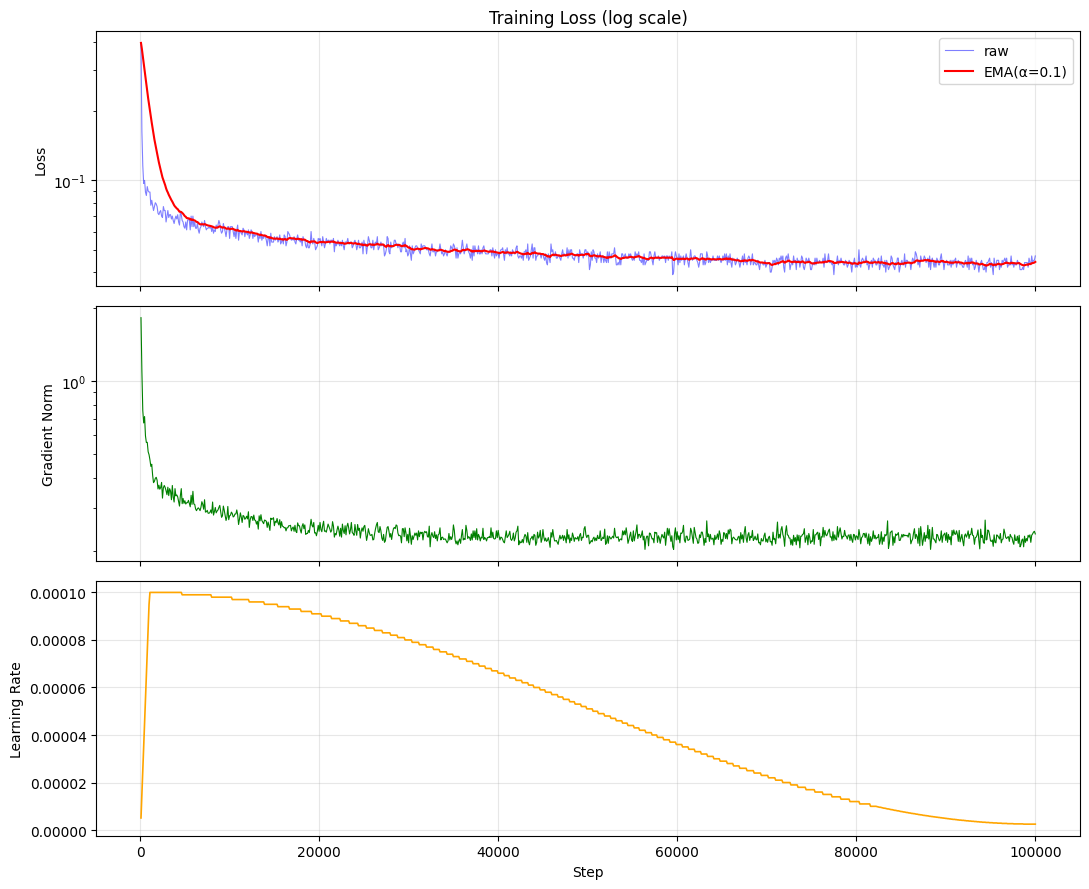


圖已存至: /home/teddyminelab/openarm_isaaclab/outputs/finetune_smolvla_basket_consistent/training_curves.png

=== 訓練摘要 ===
  Total steps        : 100,000 / 100,000
  Loss start         : 0.3950
  Loss end           : 0.0470
  Loss min           : 0.0390  @ step 59,500
  Loss last 50 pts mean: 0.0436
  Grdn start / end   : 1.825 / 0.235
  Grdn max           : 1.825  @ step 100
  LR peak            : 1.00e-04


In [10]:
import json
import re
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

NB_PATH = Path("/home/teddyminelab/openarm_isaaclab/notebooks/finetune_pi05_basket_100k.ipynb")
OUT_DIR = Path(TRAIN_OUTPUT_DIR) if "TRAIN_OUTPUT_DIR" in dir() else Path(
    "/home/teddyminelab/openarm_isaaclab/outputs/finetune_basket_v2_100k"
)

# ── 1. 從 notebook stdout 抽訓練 log ──────────────────────────────
nb = json.loads(NB_PATH.read_text())
log_chunks = []
for cell in nb["cells"]:
    if cell["cell_type"] != "code":
        continue
    for output in cell.get("outputs", []):
        t = output.get("text", "")
        if isinstance(t, list):
            t = "".join(t)
        if "loss:" in t and "grdn:" in t:
            log_chunks.append(t)
full = "\n".join(log_chunks)

# 範例: "Training: 4%| | 1100/30000 [...]INFO ... loss:0.395 grdn:1.825 lr:5.1e-06"
pat = re.compile(
    r"(\d+)/(\d+)\s*\[.*?\].*?loss:([\d.eE+\-]+)\s+grdn:([\d.eE+\-]+)\s+lr:([\d.eE+\-]+)"
)
records = {}  # step -> dict（去重）
for m in pat.finditer(full):
    step = int(m.group(1))
    records[step] = {
        "step":  step,
        "total": int(m.group(2)),
        "loss":  float(m.group(3)),
        "grdn":  float(m.group(4)),
        "lr":    float(m.group(5)),
    }
if not records:
    raise RuntimeError("找不到訓練 log。請確認 Block 6 已跑且 notebook 已 Ctrl+S 存檔")

records = sorted(records.values(), key=lambda r: r["step"])
steps  = np.array([r["step"]  for r in records])
losses = np.array([r["loss"]  for r in records])
grdns  = np.array([r["grdn"]  for r in records])
lrs    = np.array([r["lr"]    for r in records])
total_steps = records[-1]["total"]

print(f"解析到 {len(records)} 個記錄點，step {steps[0]:,} ~ {steps[-1]:,} / {total_steps:,}")

# ── 2. 畫圖 ───────────────────────────────────────────────────
fig, axes = plt.subplots(3, 1, figsize=(11, 9), sharex=True)

axes[0].plot(steps, losses, "b-", linewidth=0.8, alpha=0.5, label="raw")
if len(losses) > 10:  # EMA 平滑線
    alpha_ema = 0.1
    ema = np.zeros_like(losses)
    ema[0] = losses[0]
    for i in range(1, len(losses)):
        ema[i] = alpha_ema * losses[i] + (1 - alpha_ema) * ema[i-1]
    axes[0].plot(steps, ema, "r-", linewidth=1.5, label=f"EMA(α={alpha_ema})")
axes[0].set_ylabel("Loss")
axes[0].set_yscale("log")
axes[0].grid(True, alpha=0.3)
axes[0].legend(loc="upper right")
axes[0].set_title("Training Loss (log scale)")

axes[1].plot(steps, grdns, "g-", linewidth=0.8)
axes[1].set_ylabel("Gradient Norm")
axes[1].set_yscale("log")
axes[1].grid(True, alpha=0.3)

axes[2].plot(steps, lrs, color="orange", linewidth=1.2)
axes[2].set_ylabel("Learning Rate")
axes[2].set_xlabel("Step")
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
out_png = OUT_DIR / "training_curves.png"
out_png.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(out_png, dpi=120, bbox_inches="tight")
plt.show()
print(f"\n圖已存至: {out_png}")

# ── 3. 數值摘要 ────────────────────────────────────────────────
last_n = max(1, len(losses) // 20)  # 最後 5%
argmin = int(losses.argmin())
print(f"\n=== 訓練摘要 ===")
print(f"  Total steps        : {steps[-1]:,} / {total_steps:,}")
print(f"  Loss start         : {losses[0]:.4f}")
print(f"  Loss end           : {losses[-1]:.4f}")
print(f"  Loss min           : {losses[argmin]:.4f}  @ step {steps[argmin]:,}")
print(f"  Loss last {last_n} pts mean: {losses[-last_n:].mean():.4f}")
print(f"  Grdn start / end   : {grdns[0]:.3f} / {grdns[-1]:.3f}")
print(f"  Grdn max           : {grdns.max():.3f}  @ step {steps[int(grdns.argmax())]:,}")
print(f"  LR peak            : {lrs.max():.2e}")
